In [ ]:
from google.colab import drive
drive.mount('/gdrive')

import numpy as np
import cv2
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from keras.applications import ResNet50V2
from keras.layers import Flatten, Dense, Dropout
from keras.models import Sequential

Mounted at /gdrive


In [ ]:
# Veri yolu
DATADIR = "/gdrive/My Drive/Retinal Imaging/Eyes"
CATEGORIES = ["Cataract", "Diabetic Retinopathy", "Glaucoma", "Normal"]
IMG_SIZE = 64

In [ ]:
# Tüm veriyi depolamak için liste
all_data = []

# Tüm veriyi alma fonksiyonu
def create_all_data():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                all_data.append([new_array, class_num])
            except Exception as e:
                pass

# Tüm veriyi oluşturma
create_all_data()

In [ ]:
# Giriş ve çıkış verilerini ayırma
X = []
y = []
for features, label in all_data:
    X.append(features)
    y.append(label)

In [ ]:
# Veriyi eğitim ve test setlerine ayırma
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)


In [ ]:
# Dropout oranı
dropout_rate = 0.2

# ResNet50V2 modelini oluşturma ve eğitme
base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
model = Sequential()
model.add(Dropout(dropout_rate, input_shape=(IMG_SIZE, IMG_SIZE, 3)))
model.add(base_model)
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dropout(dropout_rate))
model.add(Dense(4, activation='softmax'))


94668760/94668760 [==============================] - 4s 0us/step


In [ ]:
# Modeli derleme
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [ ]:
# Modeli eğitme
history = model.fit(np.array(x_train), np.array(y_train), epochs=10, validation_data=(np.array(x_test), np.array(y_test)))


Epoch 1/10
106/106 [==============================] - 623s 6s/step - loss: 1.1166 - accuracy: 0.5449 - val_loss: 2.2895 - val_accuracy: 0.5201
Epoch 2/10
106/106 [==============================] - 597s 6s/step - loss: 0.6988 - accuracy: 0.6739 - val_loss: 0.8403 - val_accuracy: 0.6280
Epoch 3/10
106/106 [==============================] - 583s 5s/step - loss: 0.5787 - accuracy: 0.7539 - val_loss: 0.6975 - val_accuracy: 0.7227
Epoch 4/10
106/106 [==============================] - 592s 6s/step - loss: 0.5269 - accuracy: 0.7845 - val_loss: 0.8977 - val_accuracy: 0.6185
Epoch 5/10
106/106 [==============================] - 595s 6s/step - loss: 0.4915 - accuracy: 0.7999 - val_loss: 0.6618 - val_accuracy: 0.7618
Epoch 6/10
106/106 [==============================] - 597s 6s/step - loss: 0.4419 - accuracy: 0.8144 - val_loss: 0.7986 - val_accuracy: 0.6137
Epoch 7/10
106/106 [==============================] - 580s 5s/step - loss: 0.4585 - accuracy: 0.8150 - val_loss: 0.6390 - val_accuracy: 0.7014

In [ ]:
# Eğitilmiş özellik vektörlerini alarak Gradient Boosting modelini oluşturma ve eğitme
train_features = base_model.predict(np.array(x_train))
test_features = base_model.predict(np.array(x_test))
train_features_flatten = train_features.reshape(train_features.shape[0], -1)
test_features_flatten = test_features.reshape(test_features.shape[0], -1)

gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_model.fit(train_features_flatten, y_train)

# Test verisi üzerinde sınıflandırma yapma
gb_predictions = gb_model.predict(test_features_flatten)


27/27 [==============================] - 12s 426ms/step


In [ ]:
# Model performansını değerlendirme
gb_accuracy = accuracy_score(y_test, gb_predictions)
print("Gradient Boosting Model Doğruluğu:", gb_accuracy)

print("Sınıflandırma Raporu:")
print(classification_report(y_test, gb_predictions))

Gradient Boosting Model Doğruluğu: 0.7251184834123223
Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.73      0.66      0.70       233
           1       0.97      0.96      0.97       224
           2       0.56      0.49      0.52       188
           3       0.61      0.75      0.67       199

    accuracy                           0.73       844
   macro avg       0.72      0.72      0.71       844
weighted avg       0.73      0.73      0.72       844



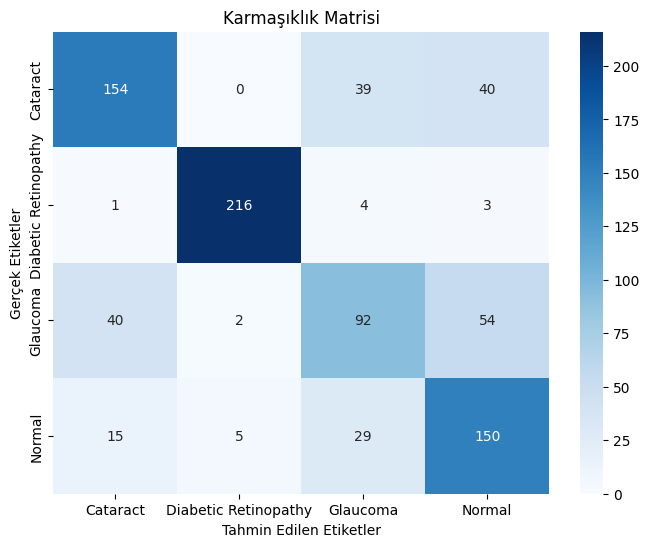

In [ ]:
# Karmaşıklık Matrisi (Confusion Matrix) görselleştirmesi
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d", xticklabels=classes, yticklabels=classes)
    plt.xlabel('Tahmin Edilen Etiketler')
    plt.ylabel('Gerçek Etiketler')
    plt.title('Karmaşıklık Matrisi')
    plt.show()

# Karmaşıklık Matrisi görselleştirmesi
plot_confusion_matrix(y_test, gb_predictions, CATEGORIES)

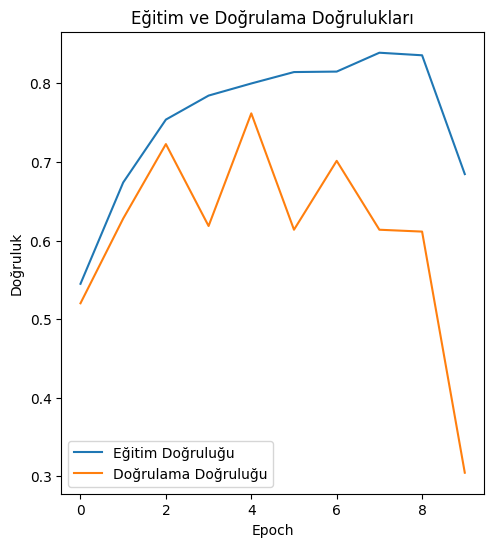

In [ ]:
# Eğitim sürecinin görselleştirilmesi
plt.figure(figsize=(12, 6))

# Eğitim ve doğrulama doğrulukları
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.xlabel('Epoch')
plt.ylabel('Doğruluk')
plt.title('Eğitim ve Doğrulama Doğrulukları')
plt.legend()

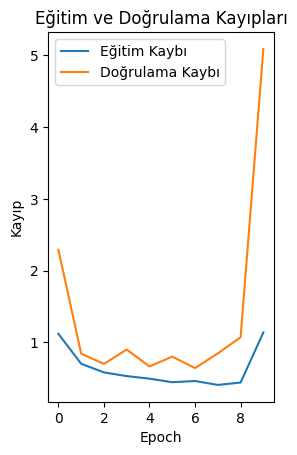

In [ ]:
# Eğitim ve doğrulama kayıpları
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.title('Eğitim ve Doğrulama Kayıpları')
plt.legend()

plt.show()